In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


In [3]:
df = pd.read_csv("Mall_Customers.csv")

In [4]:
features = ["Annual Income (k$)","Spending Score (1-100)"]
X = df[features].copy()


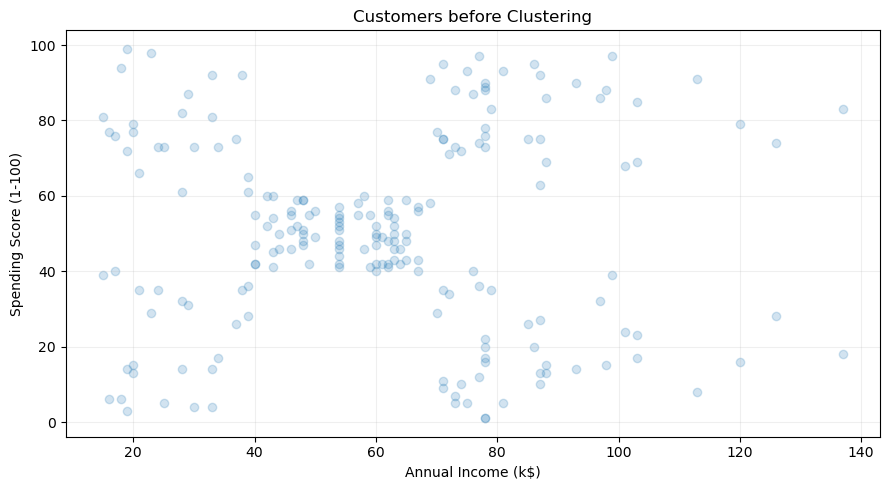

In [5]:
plt.figure(figsize=(9,5))
plt.scatter(X[features[0]],X[features[1]],alpha=0.2)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customers before Clustering")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

c:\Users\PC\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\PC\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\PC\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\PC\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

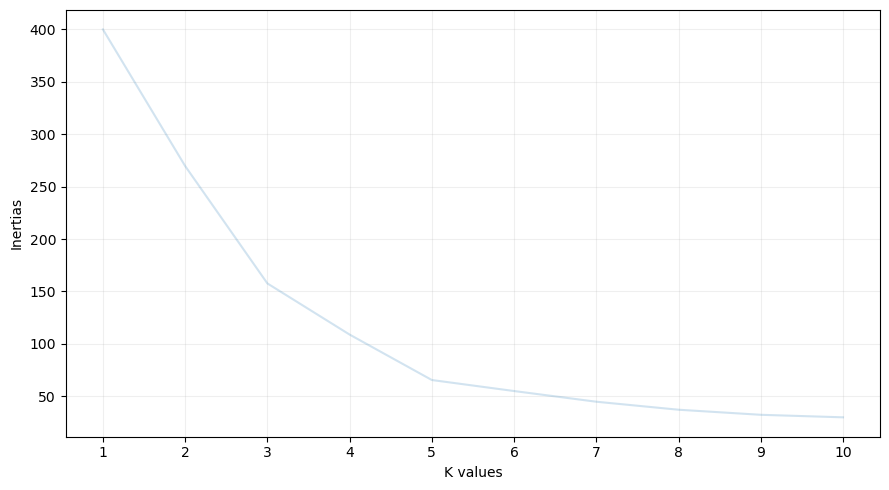

In [7]:
inertias = []
k_values = range(1,11)
for k in k_values:
    model = KMeans(n_clusters=k,random_state=42,n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(9,5))
plt.plot(list(k_values),inertias,alpha=0.2)
plt.xticks(list(k_values))
plt.xlabel("K values")
plt.ylabel("Inertias")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [8]:
kmeans = KMeans(n_clusters=5,random_state=42,n_init=10)
df["Cluster"]= kmeans.fit_predict(X_scaled)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

counts = df["Cluster"].value_counts().sort_index()
print(counts)

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


c:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


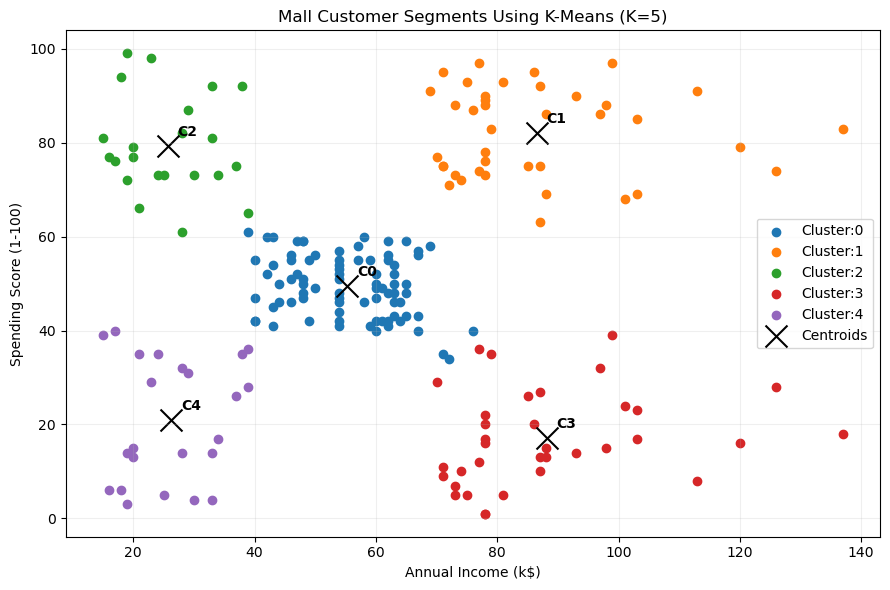

In [12]:
plt.figure(figsize=(9,6))
for cluster in sorted(df["Cluster"].unique()):
    group = df[df["Cluster"]==cluster]
    plt.scatter(group[features[0]],group[features[1]],label=f"Cluster:{cluster}",marker="o")

plt.scatter(centroids[:,0],centroids[:,1],marker="x",s=250,label="Centroids",c="black")

for i ,(income,spending) in enumerate(centroids):
    plt.annotate(f"C{i}",(income,spending),xytext=(7,7),textcoords="offset points",weight="bold")
    
    
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Mall Customer Segments Using K-Means (K=5)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("q27_customer_clusters.png", dpi=180)
plt.show()
    